# 01 · Bird Species Classification with Naive Bayes

**Portfolio recreation · synthetic data · reproducible**

This notebook explores distribution-aware **Gaussian + Uniform + Binomial** features and a Naive Bayes model built with log-likelihoods. This is an independent portfolio example, not the original Dicoding assessment template.

**Question:** Can feature distributions help distinguish synthetic bird species?

In [1]:
from pathlib import Path
import sys
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from IPython.display import Image, display
from src.bird_naive_bayes import generate_bird_data, train_test_split, fit_model, predict, evaluate
from src.visualize import save_bird_chart
import pandas as pd
import numpy as np


## 1 · Inspect the synthetic sample

Every row is simulated and does not represent field observations.

In [2]:
result = evaluate()
print('Sample size:', len(result['data']))
print('Train / test:', len(result['train']), '/', len(result['test']))
print('Species:', ', '.join(sorted(result['model'])))
display(result['data'].head())

Sample size: 960
Train / test: 720 / 240
Species: Finch, Sparrow, Swallow


,species,wingspan_cm,weight_g,beak_head_ratio,sing_days
0,Finch,18.175818,16.422078,0.242760,22
1,Finch,20.553314,17.703368,0.357870,15
2,Finch,15.638449,18.608892,0.361892,15
3,Finch,23.210275,16.859665,0.247399,18
4,Finch,21.468078,17.298290,0.369963,21


## 2 · Learn the feature distributions

Wingspan and mass use Gaussian likelihoods; beak-to-head ratio uses a bounded density; the number of singing days uses a binomial distribution.

In [3]:
for species, params in result['model'].items():
    print(species, '| prior=', round(params['prior'], 3), '| singing probability=', round(float(params['sing_prob']),3))

Finch | prior= 0.339 | singing probability= 0.633
Sparrow | prior= 0.329 | singing probability= 0.427
Swallow | prior= 0.332 | singing probability= 0.774


## 3 · Evaluation

Predictions use **log-probabilities** to avoid numerical underflow. A hold-out split is used for a transparent, reproducible accuracy figure.

Hold-out accuracy: 100.0%


predicted,Finch,Sparrow,Swallow
actual,,,
Finch,76,0,0
Sparrow,0,83,0
Swallow,0,0,81


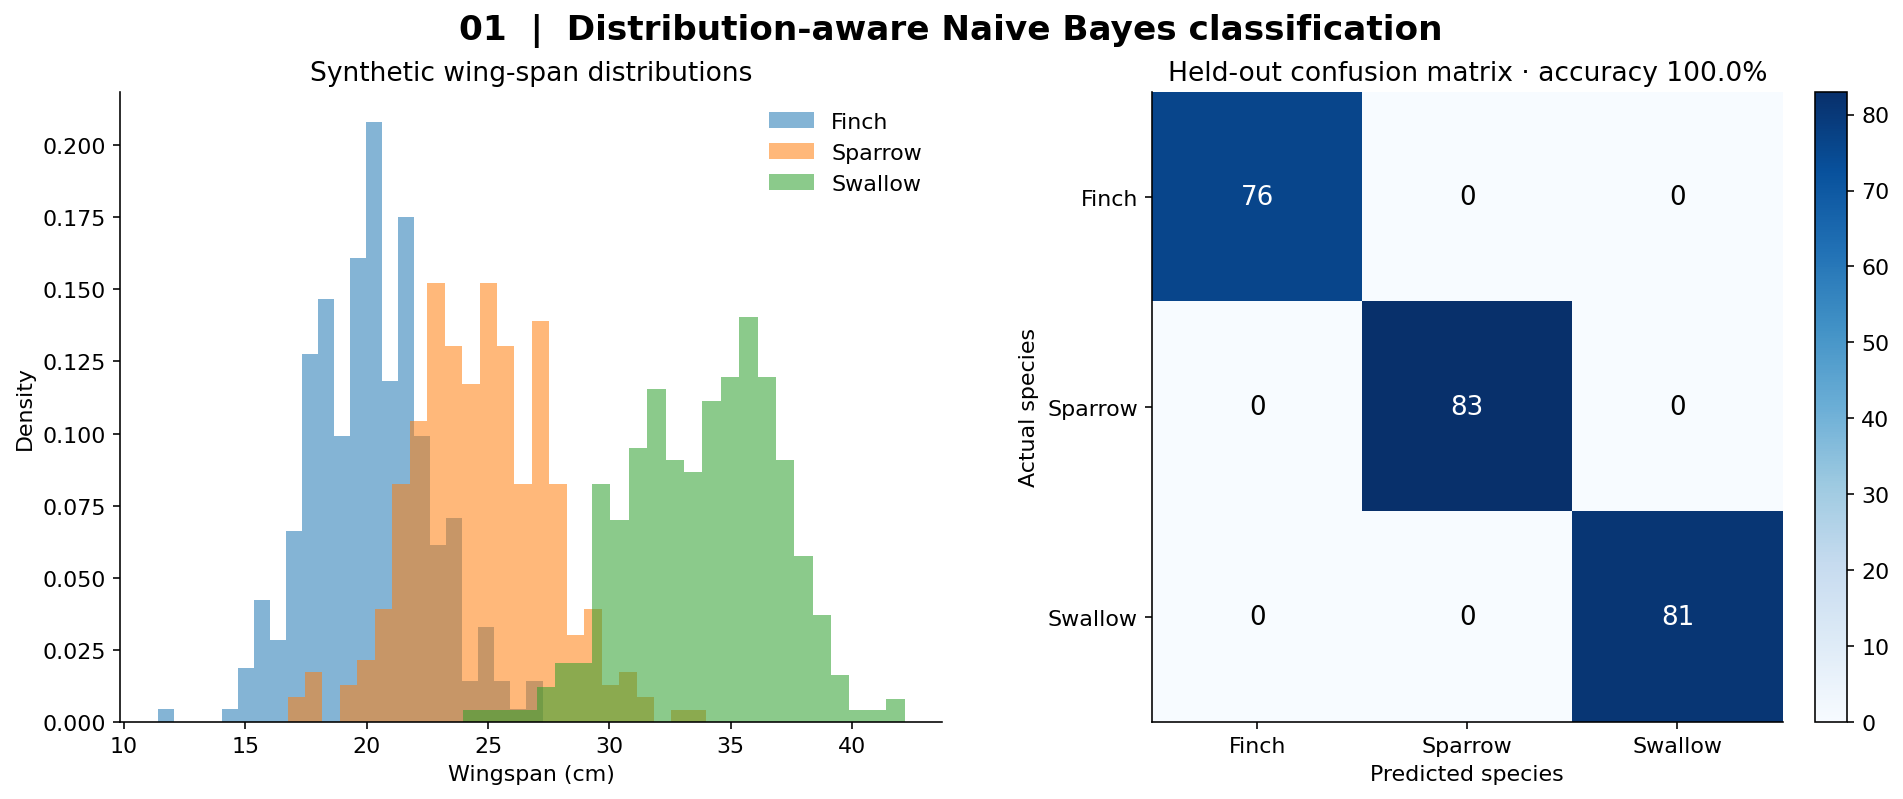

In [4]:
print('Hold-out accuracy:', f"{result['accuracy']:.1%}")
display(result['confusion'])
chart_path, _ = save_bird_chart()
display(Image(filename=str(chart_path)))

## Takeaways and limitations

- Density assumptions make model behaviour easier to explain than an opaque classifier.
- On this deliberately separable synthetic dataset, performance is high. **This is not evidence of accuracy on real birds.**
- More realistic experiments should use field-collected data, stratified splits, cross-validation, calibration, and checks for dataset shift.
- This portfolio variant uses log-probabilities (an enhancement suggested by the course reviewer).